In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
import struct
from pathlib import Path
%matplotlib inline

In [49]:
np.random.seed(42)

def read_images(file_name):
    path = "/content/" + file_name

    with open(path, "rb") as file:
        magic, count, rows, cols = struct.unpack(">IIII", file.read(16))
        if magic != 2051:
            raise ValueError(f"Неверный формат {path}")

        data = file.read()
        images = np.frombuffer(data, dtype=np.uint8)

    return images.reshape(count, rows, cols)

def read_labels(file_name):
  path = "/content/" + file_name

  with open(path, "rb") as file:
      magic, count = struct.unpack(">II", file.read(8))
      if magic != 2049:
          raise ValueError(f"Неверный формат файла меток {path}")

      data = file.read()
      labels = np.frombuffer(data, dtype=np.uint8)

  return labels

x_train = read_images("train-images.idx3-ubyte")
y_train_numbers = read_labels("train-labels.idx1-ubyte")

x_test = read_images("t10k-images.idx3-ubyte")
y_test_numbers = read_labels("t10k-labels.idx1-ubyte")

In [50]:
print("Изображения для обучения:", x_train.shape)
print("Метки для обучения:", y_train.shape)
print("Тестовые изображения:", x_test.shape)
print("Тестовые метки:", y_test.shape)

Изображения для обучения: (60000, 28, 28)
Метки для обучения: (60000, 10)
Тестовые изображения: (10000, 28, 28)
Тестовые метки: (10000, 10)


<Figure size 1000x400 with 0 Axes>

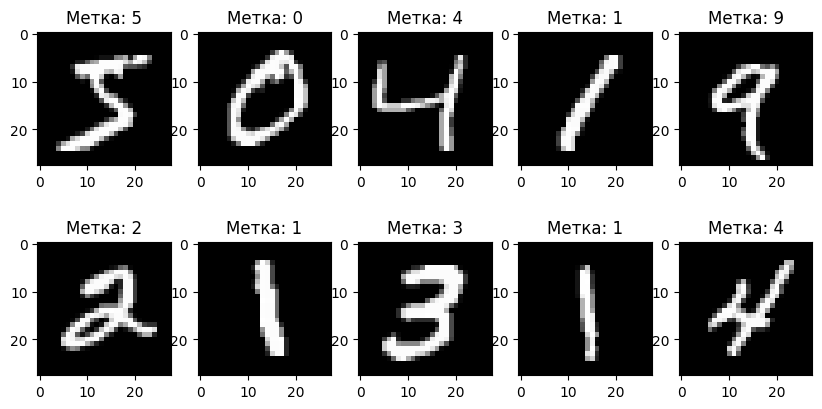

In [51]:
plt.figure(figsize=(10, 4))
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Метка: {y_train_numbers[i]}")

plt.show()

In [52]:
from sklearn.preprocessing import LabelBinarizer
lb = LabelBinarizer()

x_train = x_train.reshape(len(x_train), 784).astype(np.float32) / 255.0
x_test = x_test.reshape(len(x_test), 784).astype(np.float32) / 255.0

y_train = lb.fit_transform(y_train_numbers)
y_test = lb.transform(y_test_numbers)

In [53]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(60000, 784)
(60000, 10)
(10000, 784)
(10000, 10)


In [54]:
input_size = 784
hidden_size = 300
output_size = 10

w1 = (np.random.randn(input_size, hidden_size) * np.sqrt(2.0 / input_size)).astype(np.float32)
b1 = np.zeros((1, hidden_size), dtype=np.float32)

w2 = (np.random.randn(hidden_size, output_size) * np.sqrt(1.0 / hidden_size)).astype(np.float32)
b2 = np.zeros((1, output_size), dtype=np.float32)

In [55]:
def softmax(values):
    values = values - np.max(values, axis=1, keepdims=True)
    exp_values = np.exp(values)
    return exp_values / np.sum(exp_values, axis=1, keepdims=True)


def forward(images):
    z1 = np.dot(images, w1) + b1
    a1 = np.maximum(z1, 0)

    z2 = np.dot(a1, w2) + b2
    probabilities = softmax(z2)

    saved = (images, z1, a1, probabilities)
    return probabilities, saved


def cross_entropy(probabilities, answers):
    probabilities = np.clip(probabilities, 1e-8, 1.0)
    return -np.sum(answers * np.log(probabilities)) / len(answers)


def backward(answers, saved):
    images, z1, a1, probabilities = saved
    batch_count = len(images)

    dz2 = (probabilities - answers) / batch_count
    dw2 = np.dot(a1.T, dz2)
    db2 = np.sum(dz2, axis=0, keepdims=True)
    da1 = np.dot(dz2, w2.T)
    dz1 = da1 * (z1 > 0)
    dw1 = np.dot(images.T, dz1)
    db1 = np.sum(dz1, axis=0, keepdims=True)

    return dw1, db1, dw2, db2


def get_accuracy(images, labels, batch_size=512):
    correct = 0

    for start in range(0, len(images), batch_size):
        x_batch = images[start:start + batch_size]
        probabilities, _ = forward(x_batch)

        predictions = np.argmax(probabilities, axis=1)
        correct += np.sum(predictions == labels[start:start + batch_size])

    return correct / len(images)

In [56]:
learning_rate = 0.1
batch_size = 64
epochs = 20

train_losses = []
train_accuracies = []
epoch_times = []

for epoch in range(epochs):
    start_time = time.time()
    order = np.random.permutation(len(x_train))
    total_loss = 0.0
    num_image = 0

    for start in range(0, len(x_train), batch_size):
        batch_ids = order[start:start + batch_size]
        x_batch = x_train[batch_ids]
        y_batch = y_train[batch_ids]

        probabilities, saved = forward(x_batch)
        total_loss += cross_entropy(probabilities, y_batch) * len(x_batch)
        num_image += len(x_batch)

        dw1, db1, dw2, db2 = backward(y_batch, saved)

        w1[:] -= learning_rate * dw1
        b1[:] -= learning_rate * db1
        w2[:] -= learning_rate * dw2
        b2[:] -= learning_rate * db2

    epoch_loss = total_loss / num_image
    train_accuracy = get_accuracy(x_train, y_train_numbers)
    elapsed = time.time() - start_time

    train_losses.append(epoch_loss)
    train_accuracies.append(train_accuracy)
    epoch_times.append(elapsed)

    print(
        f"Эпоха {epoch + 1}: "
        f"точность = {train_accuracy:.4f}, "
        f"ошибка классификации = {1 - train_accuracy:.4f}, "
        f"время = {elapsed:.1f} сек"
    )

Эпоха 1: точность = 0.9317, ошибка классификации = 0.0683, время = 2.5 сек
Эпоха 2: точность = 0.9544, ошибка классификации = 0.0456, время = 4.2 сек
Эпоха 3: точность = 0.9656, ошибка классификации = 0.0344, время = 2.4 сек
Эпоха 4: точность = 0.9729, ошибка классификации = 0.0271, время = 2.4 сек
Эпоха 5: точность = 0.9744, ошибка классификации = 0.0256, время = 2.5 сек
Эпоха 6: точность = 0.9807, ошибка классификации = 0.0193, время = 4.2 сек
Эпоха 7: точность = 0.9831, ошибка классификации = 0.0169, время = 2.6 сек
Эпоха 8: точность = 0.9855, ошибка классификации = 0.0145, время = 2.6 сек
Эпоха 9: точность = 0.9877, ошибка классификации = 0.0123, время = 2.6 сек
Эпоха 10: точность = 0.9886, ошибка классификации = 0.0114, время = 4.0 сек
Эпоха 11: точность = 0.9908, ошибка классификации = 0.0092, время = 3.0 сек
Эпоха 12: точность = 0.9910, ошибка классификации = 0.0090, время = 2.5 сек
Эпоха 13: точность = 0.9933, ошибка классификации = 0.0067, время = 2.6 сек
Эпоха 14: точность = 

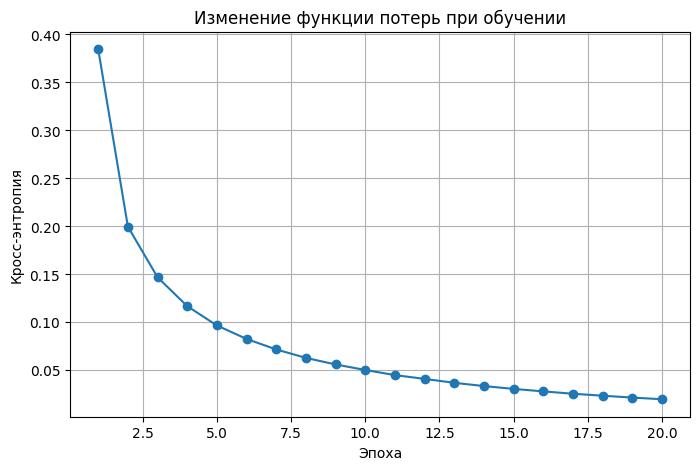

In [57]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), train_losses, marker="o")
plt.xlabel("Эпоха")
plt.ylabel("Кросс-энтропия")
plt.title("Изменение функции потерь при обучении")
plt.grid(True)
plt.show()

In [58]:
test_accuracy = get_accuracy(x_test, y_test_numbers)

In [59]:
print(f"Точность на обучающей выборке: {train_accuracies[-1] * 100:.3f}%")
print(f"Точность на тестовой выборке: {test_accuracy * 100:.3f}%")

Точность на обучающей выборке: 99.732%
Точность на тестовой выборке: 98.030%
